# persistance/03 — obstacle robustness *(behaviour, oracle-judged)*

How robust is Qwen2.5-Coder-32B-Instruct when its frontier line is **forced to start with a misleading
prefix**? For each sub-goal g_k we append a hand-curated *escapable* obstacle after the `{var} =` pivot,
greedy-generate the rest of the line, and a bespoke oracle (`obstacle_eval.judge_adapts`) grades the full
right-hand side: **ADAPTED** (implements g_k, working around the forced stub — any valid impl, so it
honours plasticity), **SUCCUMBED** (followed the stub to the wrong op), **ESCAPED** (reaches g_k but by
degenerately discarding the stub), **BROKEN** (invalid/incomplete).

Two difficulty levels: **easy** (ignorable identities — `True and`, `0 +`, `(`) and **hard** (forced
wrong sibling `((wrong)` or a wrong-op fragment `- 1 +`). `aligned` = correct start (ceiling control).
Prefills: `scripts/evaluation/obstacle_prefills.py` (all 64 predicates, escapability-verified).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5")   # 32B ~63GB; set to a free GPU
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import matplotlib.pyplot as plt
import torch
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.markup import escape
from src.utils import logging_utils, env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)   # anchor CWD+imports to repo root
logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

## 0. Model

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print("loaded", MODEL_NAME)

2026-09-20 19:27:20 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-09-20 19:27:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:27:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 19:27:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:27:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 19:27:20 httpx INFO     HTTP Re

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-20 19:27:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:27:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-09-20 19:27:43 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
loaded Qwen/Qwen2.5-Coder-32B-Instruct


## 1. Corpus + obstacle prompts

A **minimal single-predicate prompt** per predicate: signature + a one-item task list, ending at the
frontier `    a =`. We append an obstacle prefix after the `=`, greedy-generate the rest of the line,
and take the full right-hand side.

In [3]:
import src.diff.data as D
from scripts.evaluation.eval_goalscope import _chat_prompt, greedy_continue
from scripts.evaluation.obstacle_prefills import OBSTACLE_PREFILLS, ARG
from scripts.evaluation.obstacle_eval import judge_adapts
from src.tokens import prepare_input

RES_VAR = "a"    # frontier result variable in the minimal prompt

def build_obstacle_prompt(dt, pid, prefix):
    """(prompt_ending_with_the_appended_prefix, predicate). Prompt = signature + `(1) desc` + `    a =` + prefix."""
    bank = D.QTASKS[dt]; arg = ARG[dt]
    p = next(x for x in bank.predicates if x.id == pid)
    q = D._question([p.description], dt, arg, "python", "listed")
    sig = D._signature(dt, arg, "python")
    base = "<code>\n" + sig + "\n    " + RES_VAR + " ="
    return _chat_prompt(mt, q, base) + prefix, p

@torch.no_grad()
def run_obstacle(dt, pid, prefix, max_new=48):
    """Greedy-continue after the forced prefix; return (rhs, prompt, gen). rhs = full first-line RHS."""
    prompt, p = build_obstacle_prompt(dt, pid, prefix)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    gen = greedy_continue(mt, **inp, max_new_tokens=max_new)
    rhs = (prefix + gen).split("\n")[0].strip()          # everything after `a =`, first line
    return rhs, prompt, gen, p

# smoke: one easy + one hard on int/is_even (no oracle call yet)
_r, _pr, _g, _p = run_obstacle("int", "is_even", OBSTACLE_PREFILLS["int"]["is_even"]["hard"][0])
print("hard[0] stub :", OBSTACLE_PREFILLS["int"]["is_even"]["hard"][0])
print("RHS          :", _r)


# ── GoalScope read-out at the last prompt token (for eyeballing; NOT judged) ──
from scripts.evaluation.eval_goalscope import load_json_heads
from src.goals.goalscope import apply_goalscope
_HEADS = f"head_sets/{MODEL_NAME.split('/')[-1]}/goal_topk/goal__lam20_top250.json"
goal_heads = load_json_heads(_HEADS, mt.n_layer, mt.n_heads)
GS = dict(selected_heads=goal_heads, strategy="additive_norm", alpha=0.1,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=48)

@torch.no_grad()
def readout_at(prompt):
    """GoalScope NL verbalization at the LAST token of `prompt` (single-shot; not judged)."""
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    pos = inp.input_ids.shape[1] - 1
    r = apply_goalscope(inp, mt=mt, show=False, include_noncode=False, token_positions=[pos], **GS)
    return (r[0].get("patched_gen") or "").strip() if r else ""


hard[0] stub :  (((n > 0))
RHS          : (((n > 0)) & ((n % 2) == 0))


## 2. Vibe-check — a few examples per level (with oracle verdict)

Panels: the appended obstacle, the full RHS the model produced, and the `judge_adapts` verdict. Look for
whether hard obstacles get ADAPTED (robust) vs SUCCUMBED (broke).

In [4]:
def show_example(dt, pid, level, k=0):
    spec = OBSTACLE_PREFILLS[dt][pid]
    prefix = spec[level][k]
    rhs, prompt, gen, p = run_obstacle(dt, pid, prefix)       # perturbed prompt ends at `a =` + prefix
    _, clean_prompt, clean_gen, _ = run_obstacle(dt, pid, "") # clean prompt ends at `a =` (NOT judged)
    ro_clean = readout_at(clean_prompt)                        # GoalScope @ last token (the `=` pivot)
    ro_obs   = readout_at(prompt)                              # GoalScope @ last token (end of prefix)
    v = judge_adapts(p.description, prefix, rhs)
    color = {"ADAPTED":"sea_green3","ESCAPED":"yellow","SUCCUMBED":"salmon1","BROKEN":"grey58"}.get(v["verdict"],"white")
    gen_line   = gen.split("\n")[0]
    clean_line = clean_gen.split("\n")[0]
    body = (
        f"[bold]{escape(dt)} · {escape(pid)}[/bold]  [grey58]({level})[/grey58]\n"
        f"[grey58]sub-goal:[/grey58] {escape(p.description)}\n"
        f"[grey58]── full prompt (clean, ends at `a =`; obstacle appends the [salmon1]salmon[/salmon1]) ──[/grey58]\n"
        f"[white]{escape(clean_prompt)}[/white][salmon1]{escape(prefix)}[/salmon1]\n"
        f"[grey58]── GoalScope read-out @ last prompt token (not judged) ──[/grey58]\n"
        f"[grey58]clean pivot (`=`):[/grey58] [sea_green3]{escape(ro_clean)}[/sea_green3]\n"
        f"[grey58]obstacle pivot   :[/grey58] [salmon1]{escape(ro_obs)}[/salmon1]\n"
        f"[grey58]── generation ──[/grey58]\n"
        f"[grey58]clean   :[/grey58] [grey58]a =[/grey58][sea_green3]{escape(clean_line)}[/sea_green3]\n"
        f"[grey58]obstacle:[/grey58] [grey58]a =[/grey58][salmon1]{escape(prefix)}[/salmon1][bright_yellow]{escape(gen_line)}[/]\n"
        f"[grey58]verdict :[/grey58] [{color}]{v['verdict']}[/{color}] — {escape(v['rationale'])}"
    )
    rich_print(Panel(Text.from_markup(body), border_style="grey42", padding=(0,1)))

# 4 easy + 4 hard across datatypes
picks = [("int","is_even"), ("str","has_digit"), ("list[int]","has_even"), ("list[str]","count_long")]
for lvl in ("easy","hard"):
    rich_print(f"[bold underline]{lvl.upper()}[/bold underline]  [grey58](salmon = forced prefix · yellow = LM continuation · green = clean/unperturbed)[/grey58]")
    for dt, pid in picks:
        show_example(dt, pid, lvl, k=0)


EASY  (salmon = forced prefix · yellow = LM continuation · green = clean/unperturbed)

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ int · is_even  (easy)                                                                                           │
│ sub-goal: whether the number is even                                                                            │
│ ── full prompt (clean, ends at `a =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given an integer `n`, computes:                 │
│ (1) whether the number is even                                                                                  │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(n: int):                                                                                               │
│     a = True and                                                                                                │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): Checking if the number is even.                                                              │
│ obstacle pivot   : I'm evaluating whether the current line of code is executing based on a condition that       │
│ checks if the variable `x` is even (i.e., `x % 2 == 0`).                                                        │
│ ── generation ──                                                                                                │
│ clean   : a = n % 2 == 0                                                                                        │
│ obstacle: a = True and 1 == 1                                                                                   │
│ verdict : SUCCUMBED — `True and 1 == 1` always evaluates to `True` regardless of whether the number is even or  │
│ odd — it doesn't check parity at all.                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[int] · has_even  (hard)                                                                                    │
│ sub-goal: whether any value is even                                                                             │
│ ── full prompt (clean, ends at `a =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of integers `nums`, computes:      │
│ (1) whether any value is even                                                                                   │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(nums: list[int]):                                                                                      │
│     a = ((len(set(nums)) != len(nums))                                                                          │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): Checking if any element in the list is True (i.e., if there's an even number).               │
│ obstacle pivot   : I'm checking if there's a duplicate element in the list by using a set to determine if the   │
│ length of the list is not equal to the length of the set of the list.                                           │
│ ── generation ──                                                                                                │
│ clean   : a = any(x % 2 == 0 for x in nums)                                                                     │
│ obstacle: a = ((len(set(nums)) != len(nums)) or (any(x % 2 == 0 for x in nums)))                                │
│ verdict : SUCCUMBED — The full expression computes (has_duplicates OR has_even), which is not equivalent to     │
│ "whether any value is even" — the duplicate check adds an extra condition that can make the result True even    │
│ when no values are even.                                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[str] · count_long  (hard)                                                                                  │
│ sub-goal: the number of words longer than five characters                                                       │
│ ── full prompt (clean, ends at `a =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) the number of words longer than five characters                                                             │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = ((sum(len(w) for w in words))                                                                           │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): Counting variables that meet a specific condition.                                           │
│ obstacle pivot   : Counting lines longer than 5 characters.                                                     │
│ ── generation ──                                                                                                │
│ clean   : a = sum(1 for word in words if len(word) > 5)                                                         │
│ obstacle: a = ((sum(len(w) for w in words)) > 5)                                                                │
│ verdict : SUCCUMBED — The expression computes a boolean (True/False) of whether the total length of all words   │
│ exceeds 5, not the count of words longer than 5 characters.                                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 3. Scaled dose-response — ADAPTED rate by level × datatype

Runs over predicates × categories × prefixes (subsampled by the knobs). Headline = **ADAPTED rate**
(obstacle robustness); `aligned` is the ceiling. Keep `N_PRED`/`N_PER` small for a first pass, then scale.

obstacle trials:   0%|          | 0/72 [00:00<?, ?it/s]

2026-09-20 19:10:36 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:10:43 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:10:49 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:10:54 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:10:58 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:11:03 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:11:09 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:11:12 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:11:16 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20

    ADAPTED rate  (obstacle robustness)  —    
          rows=level, cols=datatype           
                                              
  level      int    str   list   list    all  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  aligned   0.83   0.83   1.00   1.00   0.92  
  easy      0.50   0.17   0.00   0.00   0.17  
  hard      0.00   0.17   0.00   0.33   0.12

       verdict breakdown by level (fraction)        
                                                    
  level     ADAPTED   ESCAPED   SUCCUMBED   BROKEN  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  aligned      0.92      0.00        0.00     0.04  
  easy         0.17      0.00        0.83     0.00  
  hard         0.12      0.00        0.75     0.12

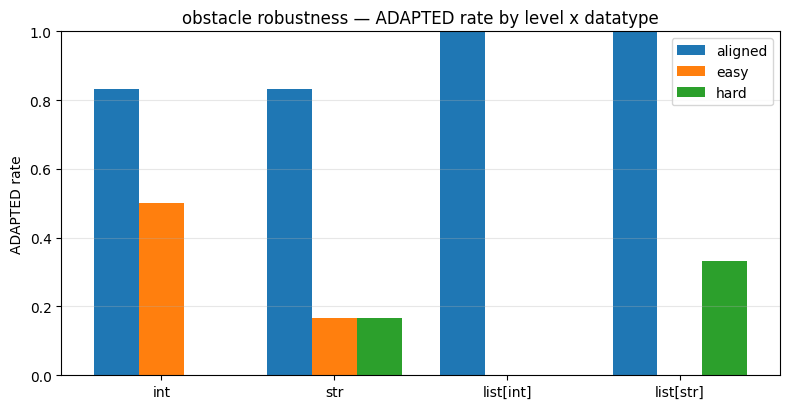

In [6]:
from collections import defaultdict
from tqdm.auto import tqdm

N_PRED = 6      # predicates per datatype (None = all 16)
N_PER  = 1      # prefixes per (predicate, category)
LEVELS = ["aligned", "easy", "hard"]
SEED   = 0

rng = random.Random(SEED)
rows = []   # (dt, pid, level, prefix, verdict)
jobs = []
for dt in ARG:
    pids = list(OBSTACLE_PREFILLS[dt])
    if N_PRED: pids = pids[:N_PRED]
    for pid in pids:
        spec = OBSTACLE_PREFILLS[dt][pid]
        for lvl in LEVELS:
            for prefix in spec[lvl][:N_PER]:
                jobs.append((dt, pid, lvl, prefix))

for dt, pid, lvl, prefix in tqdm(jobs, desc="obstacle trials"):
    rhs, *_ , p = run_obstacle(dt, pid, prefix)
    v = judge_adapts(p.description, prefix, rhs)
    rows.append(dict(dt=dt, pid=pid, level=lvl, prefix=prefix, rhs=rhs, verdict=v["verdict"]))
print(f"{len(rows)} trials")

# ADAPTED-rate table by level x datatype
def rate(sub, verd="ADAPTED"):
    return (sum(1 for r in sub if r["verdict"] == verd) / len(sub)) if sub else float("nan")

t = Table(title="ADAPTED rate  (obstacle robustness)  — rows=level, cols=datatype", box=SIMPLE_HEAVY)
t.add_column("level"); [t.add_column(dt, justify="right") for dt in ARG]; t.add_column("all", justify="right")
for lvl in LEVELS:
    cells = [f"{rate([r for r in rows if r['level']==lvl and r['dt']==dt]):.2f}" for dt in ARG]
    t.add_row(lvl, *cells, f"{rate([r for r in rows if r['level']==lvl]):.2f}")
rich_print(t)

# verdict breakdown per level
vt = Table(title="verdict breakdown by level (fraction)", box=SIMPLE_HEAVY)
vt.add_column("level"); [vt.add_column(v, justify="right") for v in ("ADAPTED","ESCAPED","SUCCUMBED","BROKEN")]
for lvl in LEVELS:
    sub = [r for r in rows if r["level"]==lvl]
    vt.add_row(lvl, *[f"{rate(sub,v):.2f}" for v in ("ADAPTED","ESCAPED","SUCCUMBED","BROKEN")])
rich_print(vt)

# bar plot: ADAPTED rate per level x datatype
fig, ax = plt.subplots(figsize=(8,4.2))
x = np.arange(len(ARG)); w = 0.26
for i, lvl in enumerate(LEVELS):
    ax.bar(x + (i-1)*w, [rate([r for r in rows if r['level']==lvl and r['dt']==dt]) for dt in ARG],
           w, label=lvl)
ax.set_xticks(x); ax.set_xticklabels(list(ARG)); ax.set_ylim(0,1)
ax.set_ylabel("ADAPTED rate"); ax.set_title("obstacle robustness — ADAPTED rate by level x datatype")
ax.legend(); ax.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()

### Notes / caveats
- **Minimal single-predicate prompt** (one sub-goal, `a =` frontier) — isolates the obstacle effect but
  is *not* the multi-predicate context of the main paper; a variant that appends the obstacle at a
  frontier inside a real multi-predicate function is a straightforward extension.
- **Oracle cost**: every trial is one `judge_adapts` call (cached). The scaled cell fans out over
  `N_PRED × 3 levels × N_PER × 4 datatypes`; raise the knobs for the real run.
- **ESCAPED vs ADAPTED**: ESCAPED = reached the goal but degenerately discarded the forced prefix; treat
  it separately from genuine adaptation when reporting robustness.
- Every obstacle is escapability-verified (`python -m scripts.evaluation.obstacle_prefills` → 0 broken),
  so a SUCCUMBED/BROKEN verdict reflects the model, not an impossible obstacle.